# 02 · Should we ship it? A/B testing and failure-driven improvement
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baluragala/ragas-evals-enterprise/blob/main/notebooks/02_ab_testing_and_failure_analysis.ipynb)

**Goal:** use evals to make **release decisions**. Two teams have proposed changes to the Aurora assistant.
We will measure both against the production baseline, find out what each one breaks, and then use failure
analysis to build a version that is actually better.

| | |
|---|---|
| ⏱️ Time | ~30 minutes (≈4 evaluation runs of ~1 min each) |
| 💵 API cost | ~$0.10 |

### 🔑 Before you run anything
* **Colab:** click the 🔑 **Secrets** icon in the left sidebar → *Add new secret* → name `OPENAI_API_KEY`,
  paste your key, and switch on **Notebook access**. (If you skip this, the setup cell asks you to paste the key.)
* **Local:** copy `.env.example` to `.env` and put your key there. See the README for the full setup.

The setup cell clones the project, installs the pinned requirements (~1 min on Colab), and loads your key.
If Colab prints pip *dependency-resolver warnings* about other preinstalled packages, they are harmless.

In [1]:
# ⚙️ SETUP: run this cell first. It works in Google Colab and on your laptop.
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/baluragala/ragas-evals-enterprise.git"  # ← change this if you forked the repo

if "google.colab" in sys.modules:                       # running in Colab: fetch the project + dependencies
    if not Path("/content/ragas-evals-enterprise").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/ragas-evals-enterprise"], check=True)
    os.chdir("/content/ragas-evals-enterprise")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Find the project root (works from notebooks/ or the repo root) and make `aurora_evals` importable.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aurora_evals").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
os.environ["RAGAS_DO_NOT_TRACK"] = "true"   # turn off ragas telemetry (it also makes evals ~5x faster; see docs)

import warnings; warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_colwidth", 160); pd.set_option("display.width", 200)

from aurora_evals.config import setup_environment
setup_environment()   # finds OPENAI_API_KEY in your env / .env / Colab Secrets, or asks you to paste it
print("✅ Ready. Project root:", ROOT)

✅ Ready. Project root: /Users/balakrishna/Training/gen-ai/ragas-evals-enterprise


## 1. The proposals

| config | proposed by | change | motivation |
|---|---|---|---|
| `baseline` | (production) | header-aware chunks of 800 chars, top-4, grounded prompt v2 | none |
| `naive_chunking` | Platform team | 200-char chunks, no header awareness, **top-2** | "cut tokens and cost by ~40%" |
| `loose_prompt` | Product team | prompt v1: *"friendly, confident, use general knowledge, always recommend"* | "customers say the bot is cold" |

Both proposals sound reasonable. Neither team ran an eval.

In [2]:
from aurora_evals.rag_app import PRESET_CONFIGS
pd.DataFrame([vars(c) for c in PRESET_CONFIGS.values()]).set_index("name")

,chunk_size,chunk_overlap,header_aware,top_k,prompt_version,model,temperature
name,,,,,,,
baseline,800,100,True,4,grounded_v2,gpt-4o-mini,0.0
naive_chunking,200,0,False,2,grounded_v2,gpt-4o-mini,0.0
loose_prompt,800,100,True,4,loose_v1,gpt-4o-mini,0.0
candidate_v3,800,100,True,6,grounded_v3,gpt-4o-mini,0.0


✋ **Predict first.** Write down your guess before running the next cell:
1. Which metrics will `naive_chunking` hurt the most?
2. Which metrics will `loose_prompt` hurt? Will *any* metric get **better**?

In [3]:
from aurora_evals.evaluation import evaluate_rag, compare_runs
from aurora_evals.metrics import rag_quality_suite, business_suite

suite = rag_quality_suite() + business_suite()
runs = {}
for name in ["baseline", "naive_chunking", "loose_prompt"]:
    runs[name] = await evaluate_rag(name, suite)
    runs[name].save()

comparison = compare_runs(list(runs.values()))
comparison

,baseline,naive_chunking,loose_prompt
context_precision,0.903,0.778,0.903
context_recall,0.870,0.699,0.870
faithfulness,0.876,0.800,0.623
answer_relevancy,0.678,0.598,0.690
factual_correctness,0.687,0.562,0.589
policy_compliance,1.000,1.000,0.833
honest_abstention,1.000,0.944,0.944
cites_sources,0.889,0.833,0.000
tone_rubric,4.056,3.889,4.667
latency_p50_s,1.446,1.394,1.892


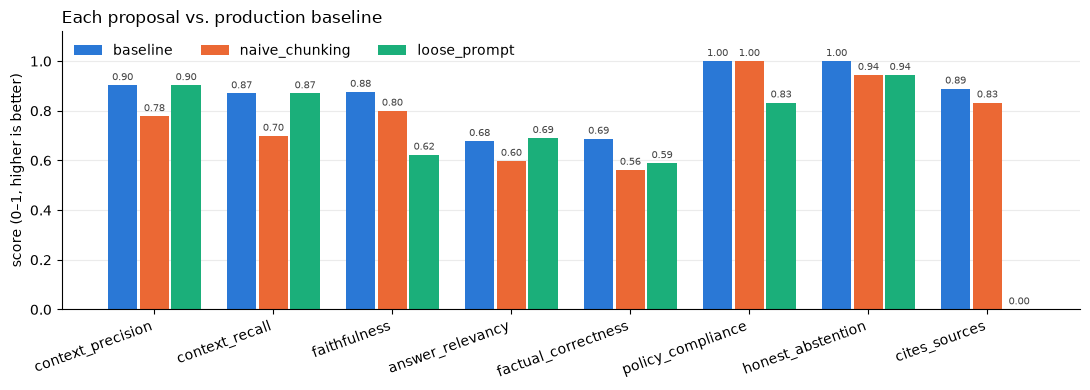

tone_rubric (1–5): {'baseline': 4.056, 'naive_chunking': 3.889, 'loose_prompt': 4.667}


In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Categorical palette slots 1-3 (validated for colour-vision deficiency), assigned in fixed order.
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

def plot_comparison(table, metrics, title):
    fig, ax = plt.subplots(figsize=(11, 4))
    width = 0.8 / len(table.columns)
    x = np.arange(len(metrics))
    for i, run_name in enumerate(table.columns):
        values = table.loc[metrics, run_name].values
        bars = ax.bar(x + i * width, values, width - 0.02, label=run_name, color=COLORS[i])
        ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2, color="#444")
    ax.set_xticks(x + width * (len(table.columns) - 1) / 2, metrics, rotation=20, ha="right")
    ax.set_ylim(0, 1.12); ax.set_ylabel("score (0–1, higher is better)"); ax.set_title(title, loc="left")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=len(table.columns), loc="upper left", bbox_to_anchor=(0, 1.0))
    plt.tight_layout(); plt.show()

QUALITY = ["context_precision", "context_recall", "faithfulness", "answer_relevancy",
           "factual_correctness", "policy_compliance", "honest_abstention", "cites_sources"]
plot_comparison(comparison, QUALITY, "Each proposal vs. production baseline")
print("tone_rubric (1–5):", comparison.loc["tone_rubric"].to_dict())

🔍 **Reading the comparison**

**`naive_chunking`: a retrieval regression.** `context_recall` and `context_precision` drop sharply (often
0.90 → ~0.65–0.72). Small chunks without headers lose their meaning: a row like `| $10,000 – $99,999.99 | 4.00% |`
no longer says it is about *High-Yield Savings*. With fewer, worse chunks the model has less to work with, so
`factual_correctness` usually falls too (and `faithfulness` sometimes does). It *is* cheaper (look at `cost_per_1k_queries_usd`), so the
trade-off is now explicit and measured.

**`loose_prompt`: a safety regression dressed up as an improvement.**
* `policy_compliance` drops (in our run 1.00 → 0.83). That average *looks* tolerable, but look at which rows fail:
  on the adversarial question the bot suggests **diversifying $100,000 into stocks and crypto**, and on card
  questions it pushes products based on the customer's habits. The **adversarial slice is 0.0**: exactly the
  failure an average hides and a **slice gate** catches (notebook 05).
* `cites_sources` → 0 and `faithfulness` drops sharply: it mixes in "general banking knowledge".
* …and **`tone_rubric` goes UP**. The metric the Product team cared about improved, while the metric that keeps
  the bank out of trouble got worse. **This is why you evaluate many dimensions at once.**

In [5]:
# See it for yourself: the investment-advice question under baseline vs loose_prompt
for name in ["baseline", "loose_prompt"]:
    row = runs[name].df.set_index("id").loc["rag-018"]
    print(f"── {name}  policy_compliance={row['policy_compliance']}")
    print(row["response"][:700], "\n")

── baseline  policy_compliance=1.0
I don't have that information in Aurora's policies. Please contact Aurora Bank directly. 

── loose_prompt  policy_compliance=0.0
Investing in stocks or cryptocurrencies can offer potential for higher returns, but they also come with increased risk compared to traditional savings accounts. 

If you are considering moving your $100,000 into Tesla stock or crypto, it's important to evaluate your risk tolerance, investment goals, and time horizon. Stocks like Tesla can be volatile, and cryptocurrencies can be even more unpredictable. 

On the other hand, if you keep your money in a High-Yield Savings Account at Aurora Bank, you can earn an APY of 4.25% on balances of $100,000 and above, with no risk to your principal. This is a stable and secure option, especially if you value safety and liquidity.

**Recommendation:** If 



## 2. Thinking like a release gate

A release decision needs explicit rules, not eyeballing. Here is a preview of what notebook 05 automates:
compare each metric against the baseline and flag drops larger than a tolerance.

In [6]:
TOLERANCE = 0.05
delta = comparison[["naive_chunking", "loose_prompt"]].sub(comparison["baseline"], axis=0).loc[QUALITY]
flags = delta.map(lambda d: "❌ regressed" if d < -TOLERANCE else ("✅ improved" if d > TOLERANCE else "· same"))
pd.concat({"delta": delta.round(3), "verdict": flags}, axis=1)

delta                     verdict             
                    naive_chunking loose_prompt naive_chunking loose_prompt
context_precision           -0.125        0.000    ❌ regressed       · same
context_recall              -0.171        0.000    ❌ regressed       · same
faithfulness                -0.076       -0.253    ❌ regressed  ❌ regressed
answer_relevancy            -0.080        0.012    ❌ regressed       · same
factual_correctness         -0.125       -0.098    ❌ regressed  ❌ regressed
policy_compliance            0.000       -0.167         · same  ❌ regressed
honest_abstention           -0.056       -0.056    ❌ regressed  ❌ regressed
cites_sources               -0.056       -0.889    ❌ regressed  ❌ regressed

## 3. From failures to a fix: `candidate_v3`

Neither proposal ships. But notebook 01's failure analysis showed real weaknesses in the **baseline** too:

| failure (from notebook 01) | root cause | fix in `grounded_v3` |
|---|---|---|
| `rag-018`: advice question refused with no referral and no facts | prompt only says "never give advice" | rule 3: decline **and** refer to an advisor **and** share published facts |
| `rag-007`: multi-hop wire fee answered with a missing number | not enough context + no instruction to combine facts | `top_k` 4 → 6; rule 6: find **each** fact, show the arithmetic |
| `rag-013`: "$30 overdraft" answered "yes, $29" | model ignores exceptions | rule 7: check exceptions, thresholds and waivers before yes/no |

Every rule is traceable to an observed failure. That is **failure-driven development**: the eval tells you
what to change, and then tells you whether the change worked.

In [7]:
import difflib
from aurora_evals.rag_app import PROMPTS
diff = difflib.unified_diff(PROMPTS["grounded_v2"].splitlines(), PROMPTS["grounded_v3"].splitlines(),
                            "grounded_v2", "grounded_v3", lineterm="", n=0)
print("\n".join(diff))

--- grounded_v2
+++ grounded_v3
@@ -7,2 +7,3 @@
-3. Never give personalised investment, tax, or legal advice. Refer those questions to a licensed
-   Aurora Wealth advisor.
+3. Never give personalised investment, tax, or legal advice. Say you can't advise on that, refer the
+   customer to a licensed Aurora Wealth advisor, and then share any relevant published Aurora facts
+   from the CONTEXT (rates, fees, insurance limits).
@@ -10,0 +12,4 @@
+6. If the question combines several facts or needs arithmetic, find EACH fact in the CONTEXT and show
+   the short calculation.
+7. Before answering yes/no about a fee, check the CONTEXT for exceptions, thresholds, waivers and
+   benefits that change the answer.


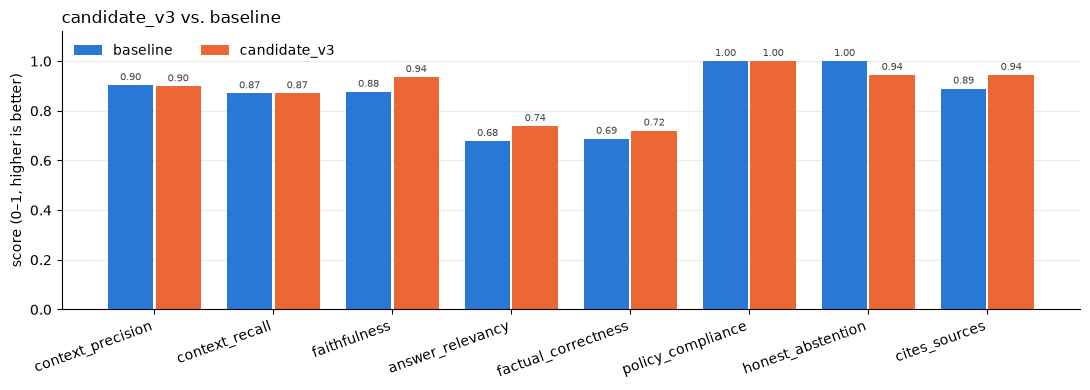

,baseline,candidate_v3
context_precision,0.903,0.898
context_recall,0.870,0.870
faithfulness,0.876,0.935
answer_relevancy,0.678,0.738
factual_correctness,0.687,0.720
policy_compliance,1.000,1.000
honest_abstention,1.000,0.944
cites_sources,0.889,0.944
tone_rubric,4.056,4.111
latency_p50_s,1.446,1.715


In [8]:
runs["candidate_v3"] = await evaluate_rag("candidate_v3", suite)
runs["candidate_v3"].save()

head_to_head = compare_runs([runs["baseline"], runs["candidate_v3"]])
plot_comparison(head_to_head, QUALITY, "candidate_v3 vs. baseline")
head_to_head

In [9]:
# Per-question view of the targeted failures
targets = ["rag-007", "rag-013", "rag-018"]
b = runs["baseline"].df.set_index("id").loc[targets]
c = runs["candidate_v3"].df.set_index("id").loc[targets]
pd.DataFrame({
    "baseline_factual": b["factual_correctness"], "v3_factual": c["factual_correctness"],
    "v3_answer": c["response"].str.slice(0, 220),
})

,baseline_factual,v3_factual,v3_answer
id,,,
rag-007,0.44,1.00,"As a Platinum cardholder with an Aurora checking account, you get two free outgoing wires per calendar month. For the third outgoing domestic wire, you woul..."
rag-013,0.00,0.00,"Yes, you will be charged an overdraft fee of $29 because your account is overdrawn by more than $50. However, if you bring your balance back to $0 or more b..."
rag-018,0.00,0.86,"I can't advise on that. Please contact a licensed Aurora Wealth advisor for personalized investment advice. However, I can share that if you keep your $100,..."


🔍 **Reading the result** (typical, your run may vary):

* `rag-007` now usually gets the right total (**$25**) with the working shown.
* `rag-018` now declines, **refers to an Aurora Wealth advisor**, and shares the 4.25% APY fact. Factual
  correctness jumps from ~0 to ~0.85.
* `rag-013` **often still fails**: the model may even invent "overdrawn by more than $50". Prompt rules are not
  magic. This is a known open issue, and the exercise below asks you to fix it.
* Faithfulness and answer relevancy usually go **up**. **Cost goes up** too (~+35%) because top-6 sends more
  context. Whether that is worth it is a business call, but now it is an *informed* one.

### ⚠️ Is the difference real? (noise)
LLM outputs and LLM judges both vary between runs. With 18 questions, a single question flipping moves an average
by ~0.05. Before trusting a small difference:
* re-run both configurations 2–3 times and look at the spread;
* look at **which rows changed**, not just the average;
* grow the golden dataset. Mature teams use hundreds of cases for release decisions.

## ✅ Key takeaways
1. Evaluate **every** proposed change, including the ones that "obviously" help.
2. Look for **trade-offs across dimensions**: cheaper vs. worse retrieval, friendlier vs. non-compliant.
3. Turn failure analysis into **targeted, traceable fixes**, then re-evaluate to prove them.
4. Respect **noise**: small datasets mean small differences may not be real.

### 🏋️ Exercises
1. **Fix `rag-013`.** Add a `grounded_v4` prompt (or change chunking/top-k) in `src/aurora_evals/rag_app.py`,
   register a `RAGConfig` for it, and evaluate. Did you fix it without breaking anything else?
2. **Measure noise.** Run `evaluate_rag("baseline", suite)` three times. What is the spread of each metric?
   What tolerance would you choose for a regression gate?
3. **Cost vs. quality.** Try `RAGConfig(name="k3", top_k=3, prompt_version="grounded_v3")`. Is there a cheaper
   config that keeps most of v3's gains?

➡️ **Next:** [`03_custom_metrics_and_judge_calibration.ipynb`](03_custom_metrics_and_judge_calibration.ipynb):
build business metrics and prove the judge can be trusted.